<a href="https://colab.research.google.com/github/Magdalene-Olivia-Govender/Quantitative-Methods-in-Finance---Financial-Markets-and-Asset-Behaviour/blob/main/SA_Inflation_Risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install pandas numpy matplotlib seaborn statsmodels scipy scikit-learn

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving south_africa_monthly.csv to south_africa_monthly.csv


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

df.head()

,date,brent_usd,headline_cpi_yoy,policy_rate,zar_usd
0,2015-08-01,0.0175,4.53,6.000,-0.78
1,2015-09-01,0.0140,4.69,6.000,4.60
2,2015-10-01,-0.0777,4.85,6.083,5.74
3,2015-11-01,-0.1459,5.02,6.250,9.73
4,2015-12-01,-0.1884,6.16,6.274,-3.75


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("south_africa_monthly.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date")

required = [
    "headline_cpi_yoy",
    "brent_usd",
    "zar_usd",
    "policy_rate"
]

df = df[required].apply(pd.to_numeric, errors="coerce")
df = df[~df.index.duplicated(keep="first")]

print(df.info())
print(df.isna().sum())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 133 entries, 2015-08-01 to 2026-08-01
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   headline_cpi_yoy  133 non-null    float64
 1   brent_usd         133 non-null    float64
 2   zar_usd           133 non-null    float64
 3   policy_rate       133 non-null    float64
dtypes: float64(4)
memory usage: 9.3 KB
None
headline_cpi_yoy    0
brent_usd           0
zar_usd             0
policy_rate         0
dtype: int64
            headline_cpi_yoy  brent_usd  zar_usd  policy_rate
date                                                         
2015-08-01              4.53     0.0175    -0.78        6.000
2015-09-01              4.69     0.0140     4.60        6.000
2015-10-01              4.85    -0.0777     5.74        6.083
2015-11-01              5.02    -0.1459     9.73        6.250
2015-12-01              6.16    -0.1884    -3.75        6.274


In [ ]:
expected_dates = pd.date_range(
    df.index.min(),
    df.index.max(),
    freq="MS"
)

print("Missing monthly dates:",
      len(expected_dates.difference(df.index)))

print("Missing values:")
print(df.isna().sum())

Missing monthly dates: 0
Missing values:
headline_cpi_yoy    0
brent_usd           0
zar_usd             0
policy_rate         0
dtype: int64


In [ ]:
#Inflation risk variables
TARGET_CHANGE_DATE = pd.Timestamp("2025-11-12")

df["inflation_target"] = np.where(
    df.index >= TARGET_CHANGE_DATE,
    3.0,   # Current point target
    4.5    # Midpoint of former 3–6% target range
)

df["target_gap"] = (
    df["headline_cpi_yoy"] - df["inflation_target"]
)

df["absolute_target_gap"] = df["target_gap"].abs()

df[[
    "headline_cpi_yoy",
    "inflation_target",
    "target_gap",
    "absolute_target_gap"
]].tail()

,headline_cpi_yoy,inflation_target,target_gap,absolute_target_gap
date,,,,
2026-04-01,4.51,3.0,1.51,1.51
2026-05-01,4.98,3.0,1.98,1.98
2026-06-01,4.26,3.0,1.26,1.26
2026-07-01,4.36,3.0,1.36,1.36
2026-08-01,0.00,3.0,-3.00,3.00


In [ ]:
#Future inflation risk gap_t_plus_ peak future risk
future_gaps = pd.concat(
    [df["absolute_target_gap"].shift(-h).rename(f"gap_t_plus_{h}")
     for h in range(1, 7)],
    axis=1
)

df["future_max_gap_6m"] = future_gaps.max(axis=1)

In [ ]:
#Future inflation sustained future risk
df["future_mean_gap_6m"] = future_gaps.mean(axis=1)

In [ ]:
#Oil price increases and rand depreciation
df["oil_change_pct"] = df["brent_usd"].pct_change() * 100

df["depreciation_pct"] = df["zar_usd"].pct_change() * 100

df[[
    "oil_change_pct",
    "depreciation_pct"
]].describe()

,oil_change_pct,depreciation_pct
count,132.000000,131.000000
mean,704.302385,-574.428462
std,8781.472930,5487.716485
min,-2333.333333,-61600.000000
25%,-174.795082,-199.648200
50%,-74.180733,-81.981982
75%,26.717601,-5.363385
max,100700.000000,9000.000000


In [ ]:
#Joint shock defined as 75th-percentile threshold among positive changes - disproportionate positive monthly change
positive_oil = df.loc[
    df["oil_change_pct"] > 0, "oil_change_pct"
]

positive_depreciation = df.loc[
    df["depreciation_pct"] > 0, "depreciation_pct"
]

oil_threshold = positive_oil.quantile(0.75)
fx_threshold = positive_depreciation.quantile(0.75)

df["joint_shock"] = (
    (df["oil_change_pct"] >= oil_threshold) &
    (df["depreciation_pct"] >= fx_threshold)
).astype(int)

print("Oil threshold:", oil_threshold)
print("Depreciation threshold:", fx_threshold)
print("Number of joint-shock months:", df["joint_shock"].sum())

Oil threshold: 288.5952534932486
Depreciation threshold: 235.53451858693143
Number of joint-shock months: 1


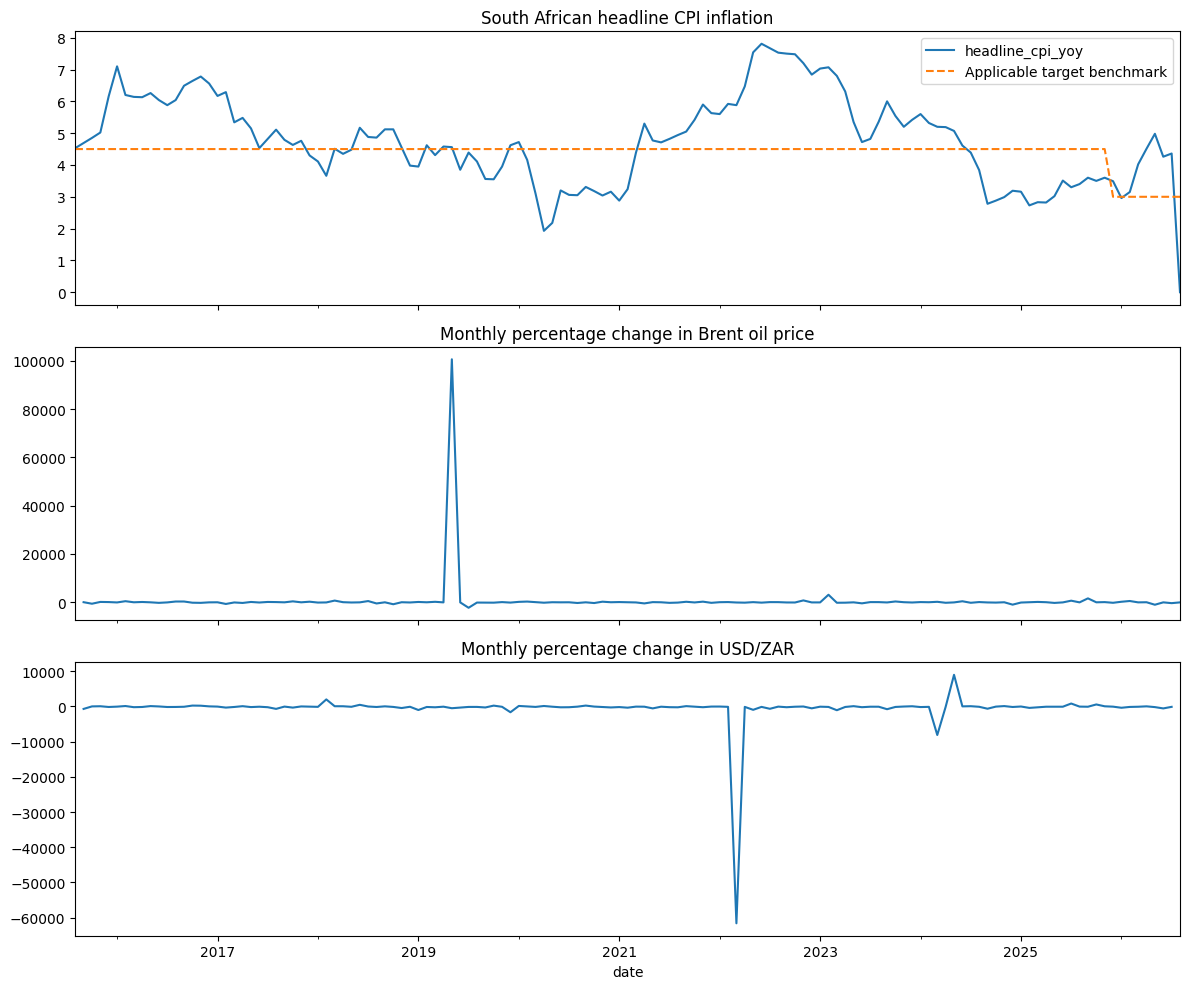

In [ ]:
# Descriptive analysis
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

df["headline_cpi_yoy"].plot(
    ax=axes[0], title="South African headline CPI inflation"
)
df["inflation_target"].plot(
    ax=axes[0], linestyle="--", label="Applicable target benchmark"
)
axes[0].legend()

df["oil_change_pct"].plot(
    ax=axes[1], title="Monthly percentage change in Brent oil price"
)

df["depreciation_pct"].plot(
    ax=axes[2], title="Monthly percentage change in USD/ZAR"
)

plt.tight_layout()
plt.show()

In [ ]:
# Comparing joint shock months with other months
comparison = (
    df.groupby("joint_shock")
      .agg(
          observations=("headline_cpi_yoy", "count"),
          mean_inflation=("headline_cpi_yoy", "mean"),
          mean_absolute_gap=("absolute_target_gap", "mean"),
          median_absolute_gap=("absolute_target_gap", "median")
      )
)

comparison.index = ["Other months", "Joint-shock months"]
print(comparison)

                    observations  mean_inflation  mean_absolute_gap  \
Other months                 132        4.779394           1.114545   
Joint-shock months             1        3.300000           1.200000   

                    median_absolute_gap  
Other months                      0.985  
Joint-shock months                1.200  


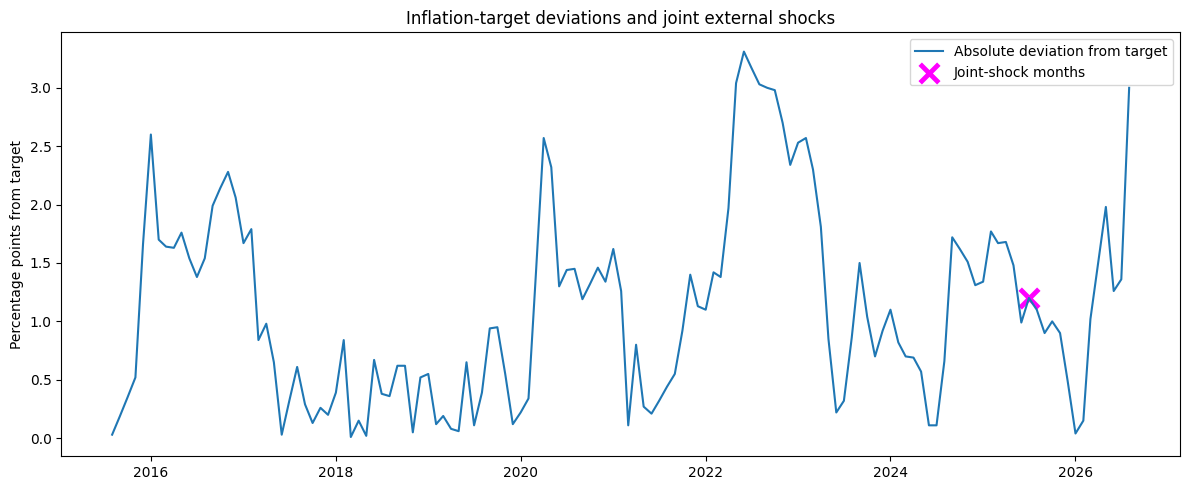

In [ ]:
# Plotting inflation risk with joint shocks noted
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["absolute_target_gap"],
    label="Absolute deviation from target"
)

shock_dates = df.index[df["joint_shock"] == 1]
ax.scatter(
    shock_dates,
    df.loc[shock_dates, "absolute_target_gap"],
    label="Joint-shock months",
    marker="x",
    s=180,           # Larger X markers
    color="#FF00FF", # Bright magenta
    linewidths=3.5    # Thicker X strokes
)
ax.set_title("Inflation-target deviations and joint external shocks")
ax.set_ylabel("Percentage points from target")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Forward looking risk outcome
future_gaps = pd.concat(
    [
        df["absolute_target_gap"].shift(-h).rename(f"gap_t_plus_{h}")
        for h in range(1, 7)
    ],
    axis=1
)

df["future_max_gap_6m"] = future_gaps.max(axis=1)
print(df.head())
print(df.tail())

            headline_cpi_yoy  brent_usd  zar_usd  policy_rate  \
date                                                            
2015-08-01              4.53     0.0175    -0.78        6.000   
2015-09-01              4.69     0.0140     4.60        6.000   
2015-10-01              4.85    -0.0777     5.74        6.083   
2015-11-01              5.02    -0.1459     9.73        6.250   
2015-12-01              6.16    -0.1884    -3.75        6.274   

            inflation_target  target_gap  absolute_target_gap  \
date                                                            
2015-08-01               4.5        0.03                 0.03   
2015-09-01               4.5        0.19                 0.19   
2015-10-01               4.5        0.35                 0.35   
2015-11-01               4.5        0.52                 0.52   
2015-12-01               4.5        1.66                 1.66   

            future_max_gap_6m  future_mean_gap_6m  oil_change_pct  \
date               

In [ ]:
# Explanatory Model - Is the joint-shock indicator associated with the future maximum target deviation, controlling for the current inflation gap, lagged core inflation and lagged policy rate?
df["gap_lag1"] = df["target_gap"].shift(1)
df["repo_lag1"] = df["policy_rate"].shift(1)

features = [
    "oil_change_pct",
    "depreciation_pct",
    "joint_shock",
    "gap_lag1",
    "repo_lag1"
]

analysis_df = df[
    ["future_max_gap_6m"] + features
].dropna()

y = analysis_df["future_max_gap_6m"]
X = sm.add_constant(analysis_df[features])

model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      future_max_gap_6m   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.208
Method:                 Least Squares   F-statistic:                     218.5
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           5.37e-60
Time:                        14:24:04   Log-Likelihood:                -140.59
No. Observations:                 131   AIC:                             293.2
Df Residuals:                     125   BIC:                             310.4
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                2.4964      0.530  

In [ ]:
print(model.summary().tables[1])

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                2.4964      0.530      4.712      0.000       1.458       3.535
oil_change_pct   -6.098e-06   1.57e-06     -3.895      0.000   -9.17e-06   -3.03e-06
depreciation_pct -1.639e-05   4.16e-06     -3.940      0.000   -2.45e-05   -8.24e-06
joint_shock         -0.1060      0.214     -0.496      0.620      -0.525       0.313
gap_lag1             0.2542      0.077      3.304      0.001       0.103       0.405
repo_lag1           -0.1409      0.082     -1.721      0.085      -0.301       0.020


In [ ]:
print("Coefficient:", model.params["joint_shock"])
print("HAC standard error:", model.bse["joint_shock"])
print("z-statistic:", model.tvalues["joint_shock"])
print("p-value:", model.pvalues["joint_shock"])
print("95% confidence interval:")
print(model.conf_int().loc["joint_shock"])

Coefficient: -0.10598542520299403
HAC standard error: 0.21355452024595573
z-statistic: -0.4962921181950546
p-value: 0.6196883263613
95% confidence interval:
0   -0.524545
1    0.312574
Name: joint_shock, dtype: float64


In [ ]:
# Is the individual joint shock statistically significant from Zero
print(
    model.t_test("joint_shock = 0")
)

                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.1060      0.214     -0.496      0.620      -0.525       0.313


In [ ]:
# Residual Autocorrelation Test
residuals = model.resid

print(
    acorr_ljungbox(
        residuals,
        lags=[3, 6, 12],
        return_df=True
    )
)

       lb_stat     lb_pvalue
3   229.863450  1.480261e-49
6   308.278593  1.375896e-63
12  321.538036  1.394332e-61


In [ ]:
# Joint Shock Only
df["gap_lag1"] = df["target_gap"].shift(1)
df["repo_lag1"] = df["policy_rate"].shift(1)

features = [
    "joint_shock",
    "gap_lag1",
    "repo_lag1"
]

analysis_df = df[
    ["future_max_gap_6m"] + features
].dropna()

y = analysis_df["future_max_gap_6m"]
X = sm.add_constant(analysis_df[features])

model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      future_max_gap_6m   R-squared:                       0.222
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     10.65
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           2.70e-06
Time:                        17:49:02   Log-Likelihood:                -141.97
No. Observations:                 131   AIC:                             291.9
Df Residuals:                     127   BIC:                             303.4
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           2.5645      0.551      4.650      

In [ ]:
# Is the individual joint shock statistically significant from Zero
print(
    model.t_test("joint_shock = 0")
)

                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.1090      0.219     -0.498      0.618      -0.537       0.320


In [ ]:
df["gap_lag1"] = df["target_gap"].shift(1)
df["repo_lag1"] = df["policy_rate"].shift(1)

features = [
    "oil_change_pct",
    "depreciation_pct",
    "gap_lag1",
    "repo_lag1"
]

analysis_df = df[
    ["future_max_gap_6m"] + features
].dropna()

y = analysis_df["future_max_gap_6m"]
X = sm.add_constant(analysis_df[features])

model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      future_max_gap_6m   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.214
Method:                 Least Squares   F-statistic:                     246.1
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           1.62e-58
Time:                        17:38:13   Log-Likelihood:                -140.60
No. Observations:                 131   AIC:                             291.2
Df Residuals:                     126   BIC:                             305.6
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                2.4980      0.529  

In [ ]:
# Oil price shock only

import pandas as pd
import numpy as np

# Work on a copy and reset index to restore 'date' as a column
df_copy = df.copy()
if 'date' not in df_copy.columns:
    df_copy = df_copy.reset_index()

df_copy["date"] = pd.to_datetime(df_copy["date"])
df_copy = df_copy.sort_values("date").reset_index(drop=True)

# If data are monthly, calculate the percentage change in Brent prices
df_copy["oil_change_pct"] = df_copy["brent_usd"].pct_change() * 100

# Use only positive oil-price changes to estimate the threshold
positive_oil_changes = df_copy.loc[
    df_copy["oil_change_pct"] > 0, "oil_change_pct"
].dropna()

oil_threshold = positive_oil_changes.quantile(0.90)

# Identify an oil shock
df_copy["oil_shock"] = (
    df_copy["oil_change_pct"] > oil_threshold
).astype("Int64")

# Avoid classifying the first missing percentage change as a non-shock
df_copy.loc[df_copy["oil_change_pct"].isna(), "oil_shock"] = pd.NA

# Count shock months
oil_shock_count = int(df_copy["oil_shock"].sum())

print(f"Oil shock threshold: {oil_threshold:.2f}% monthly increase")
print(f"Number of oil-shock months: {oil_shock_count}")
print(f"Total valid monthly observations: {df_copy['oil_change_pct'].notna().sum()}")

# Display the dates and changes associated with oil shocks
print(
    df_copy.loc[
        df_copy["oil_shock"] == 1,
        ["date", "brent_usd", "oil_change_pct"]
    ].to_string(index=False)
)

Oil shock threshold: 632.97% monthly increase
Number of oil-shock months: 5
Total valid monthly observations: 132
      date  brent_usd  oil_change_pct
2018-03-01     0.0879      644.915254
2019-05-01    -0.1008   100700.000000
2022-11-01    -0.1127      716.666667
2023-02-01    -0.0538     3064.705882
2025-09-01    -0.0467     1567.857143


In [ ]:
# Rand depreciation shocks
# Calculate monthly percentage change in ZAR per USD
# A positive change indicates rand depreciation
df["depreciation_pct"] = df["zar_usd"].pct_change() * 100

# Estimate the threshold using positive depreciation observations
positive_depreciation = df.loc[
    df["depreciation_pct"] > 0, "depreciation_pct"
].dropna()

zar_threshold = positive_depreciation.quantile(0.90)

# Identify a depreciation shock
df["zar_shock"] = (
    df["depreciation_pct"] > zar_threshold
).astype("Int64")

# Preserve missing values where the change cannot be calculated
df.loc[df["depreciation_pct"].isna(), "zar_shock"] = pd.NA

# Count shock months
zar_shock_count = int(df["zar_shock"].sum())

print(f"Rand depreciation threshold: {zar_threshold:.2f}% monthly depreciation")
print(f"Number of depreciation-shock months: {zar_shock_count}")
print(f"Total valid monthly observations: {df['depreciation_pct'].notna().sum()}")

# Display the shock dates safely by resetting the index temporarily
print(
    df.loc[df["zar_shock"] == 1, ["zar_usd", "depreciation_pct"]]
    .reset_index()
    .to_string(index=False)
)

Rand depreciation threshold: 578.12% monthly depreciation
Number of depreciation-shock months: 3
Total valid monthly observations: 131
      date  zar_usd  depreciation_pct
2018-02-01     2.11           2010.00
2024-05-01    -0.91           9000.00
2025-07-01    -1.51            843.75


In [ ]:
#Count the shocks and the thresholds
shock_summary = pd.DataFrame({
    "Shock type": [
        "Oil-price shock",
        "Rand depreciation shock"
    ],
    "Threshold (%)": [
        oil_threshold,
        zar_threshold
    ],
    "Shock months": [
        oil_shock_count,
        zar_shock_count
    ],
    "Valid observations": [
        df_copy["oil_change_pct"].notna().sum(),
        df_copy["depreciation_pct"].notna().sum() if "depreciation_pct" in df_copy.columns else df["depreciation_pct"].notna().sum()
    ]
})

display(shock_summary)

,Shock type,Threshold (%),Shock months,Valid observations
0,Oil-price shock,632.966102,5,132
1,Rand depreciation shock,578.125000,3,131


In [ ]:
import os
import pandas as pd
import numpy as np
import statsmodels.api as sm

# Dynamically locate the correct uploaded CSV file path
possible_files = ["south_africa_monthly.csv", "south_africa_monthly (1).csv"]
csv_file = next((f for f in possible_files if os.path.exists(f)), None)

if csv_file is None:
    raise FileNotFoundError("Please upload the 'south_africa_monthly.csv' file using the upload block.")

# Re-initialize the global df safely
df = pd.read_csv(csv_file)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date")

# Ensure base calculations are present in df
TARGET_CHANGE_DATE = pd.Timestamp("2025-11-12")
df["inflation_target"] = np.where(
    df.index >= TARGET_CHANGE_DATE,
    3.0,
    4.5
)
df["target_gap"] = df["headline_cpi_yoy"] - df["inflation_target"]
df["absolute_target_gap"] = df["target_gap"].abs()

# Calculate future max gap over next 6 months
future_gaps_temp = pd.concat(
    [df["absolute_target_gap"].shift(-h).rename(f"gap_t_plus_{h}")
     for h in range(1, 7)],
    axis=1
)
df["future_max_gap_6m"] = future_gaps_temp.max(axis=1)

# Recalculate oil shock on the current data
df["oil_change_pct"] = df["brent_usd"].pct_change() * 100
positive_oil_changes = df.loc[df["oil_change_pct"] > 0, "oil_change_pct"].dropna()
oil_threshold = positive_oil_changes.quantile(0.90)
df["oil_shock"] = (df["oil_change_pct"] > oil_threshold).astype("Int64")
df.loc[df["oil_change_pct"].isna(), "oil_shock"] = pd.NA

# Create lags safely
df["gap_lag1"] = df["target_gap"].shift(1)
df["repo_lag1"] = df["policy_rate"].shift(1)

# Fit the OLS model with HAC standard errors
oil_features = [
    "oil_shock",
    "gap_lag1",
    "repo_lag1"
]

oil_analysis_df = df[
    ["future_max_gap_6m"] + oil_features
].dropna()

y_oil = oil_analysis_df["future_max_gap_6m"].astype(float)
X_oil = sm.add_constant(oil_analysis_df[oil_features].astype(float))

oil_shock_model = sm.OLS(y_oil, X_oil).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(oil_shock_model.summary())

                            OLS Regression Results                            
Dep. Variable:      future_max_gap_6m   R-squared:                       0.225
Model:                            OLS   Adj. R-squared:                  0.207
Method:                 Least Squares   F-statistic:                     4.545
Date:                Thu, 29 Oct 2026   Prob (F-statistic):            0.00463
Time:                        04:53:40   Log-Likelihood:                -141.73
No. Observations:                 131   AIC:                             291.5
Df Residuals:                     127   BIC:                             303.0
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5633      0.549      4.668      0.0

In [ ]:
import os
import pandas as pd
import numpy as np
import statsmodels.api as sm

# Dynamically locate the correct uploaded CSV file path
possible_files = ["south_africa_monthly.csv", "south_africa_monthly (1).csv"]
csv_file = next((f for f in possible_files if os.path.exists(f)), None)

if csv_file is None:
    raise FileNotFoundError("Please upload the 'south_africa_monthly.csv' file using the upload block.")

# Load the dataset safely
df = pd.read_csv(csv_file)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date")

# Recalculate basic target gap metrics
TARGET_CHANGE_DATE = pd.Timestamp("2025-11-12")
df["inflation_target"] = np.where(
    df.index >= TARGET_CHANGE_DATE,
    3.0,
    4.5
)
df["target_gap"] = df["headline_cpi_yoy"] - df["inflation_target"]
df["absolute_target_gap"] = df["target_gap"].abs()

# Calculate future max gap over next 6 months
future_gaps = pd.concat(
    [df["absolute_target_gap"].shift(-h).rename(f"gap_t_plus_{h}")
     for h in range(1, 7)],
    axis=1
)
df["future_max_gap_6m"] = future_gaps.max(axis=1)

# Calculate Rand depreciation shock (using 90th percentile of positive changes)
df["depreciation_pct"] = df["zar_usd"].pct_change() * 100
positive_dep = df.loc[df["depreciation_pct"] > 0, "depreciation_pct"].dropna()
zar_threshold = positive_dep.quantile(0.90)
df["zar_shock"] = (df["depreciation_pct"] > zar_threshold).astype("Int64")
df.loc[df["depreciation_pct"].isna(), "zar_shock"] = pd.NA

# Define lag controls
df["gap_lag1"] = df["target_gap"].shift(1)
df["repo_lag1"] = df["policy_rate"].shift(1)

# Create the regression dataset
zar_features = [
    "zar_shock",
    "gap_lag1",
    "repo_lag1"
]

zar_analysis_df = df[
    ["future_max_gap_6m"] + zar_features
].dropna()

y_zar = zar_analysis_df["future_max_gap_6m"].astype(float)
X_zar = sm.add_constant(zar_analysis_df[zar_features].astype(float))

# Estimate OLS with HAC standard errors
zar_shock_model = sm.OLS(y_zar, X_zar).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(zar_shock_model.summary())

                            OLS Regression Results                            
Dep. Variable:      future_max_gap_6m   R-squared:                       0.224
Model:                            OLS   Adj. R-squared:                  0.205
Method:                 Least Squares   F-statistic:                     4.849
Date:                Thu, 29 Oct 2026   Prob (F-statistic):            0.00315
Time:                        04:53:40   Log-Likelihood:                -141.83
No. Observations:                 131   AIC:                             291.7
Df Residuals:                     127   BIC:                             303.2
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5540      0.554      4.613      0.0

In [ ]:
# Combined Model
import statsmodels.api as sm

# Define explanatory variables
combined_features = [
    "oil_shock",
    "zar_shock",
    "gap_lag1",
    "repo_lag1"
]

# Create regression dataset
combined_analysis_df = df[
    ["future_max_gap_6m"] + combined_features
].dropna()

# Define dependent and explanatory variables
y_combined = combined_analysis_df["future_max_gap_6m"]

X_combined = sm.add_constant(
    combined_analysis_df[combined_features]
)

# Estimate OLS with HAC standard errors
combined_shock_model = sm.OLS(
    y_combined,
    X_combined
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

# Display results
print(combined_shock_model.summary())

                            OLS Regression Results                            
Dep. Variable:      future_max_gap_6m   R-squared:                       0.227
Model:                            OLS   Adj. R-squared:                  0.202
Method:                 Least Squares   F-statistic:                     3.809
Date:                Thu, 29 Oct 2026   Prob (F-statistic):            0.00587
Time:                        04:54:16   Log-Likelihood:                -141.57
No. Observations:                 131   AIC:                             293.1
Df Residuals:                     126   BIC:                             307.5
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5505      0.553      4.614      0.0

In [ ]:
# Collinearity/overlap between explanatory variables
X_vif = sm.add_constant(analysis_df[features])

vif_table = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print(vif_table)

           variable       VIF
0             const  1.000000
1    oil_change_pct  1.001134
2  depreciation_pct  1.029447
3       joint_shock  1.013322
4          gap_lag1  1.042292
5         repo_lag1  1.051231


In [ ]:
%pip install statsmodels ruptures

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.8 MB/s  0:00:00


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import breaks_cusumolsresid
import ruptures as rpt

In [ ]:
#Stationarity - ADF, KPSS
stationarity_vars = [
    "headline_cpi_yoy",
    "oil_change_pct",
    "depreciation_pct",
    "policy_rate",
    "target_gap"
]

def run_stationarity_tests(series):
    x = series.dropna().astype(float)

    adf_result = adfuller(x, regression="c", autolag="AIC")
    kpss_result = kpss(x, regression="c", nlags="auto")

    return {
        "ADF statistic": adf_result[0],
        "ADF p-value": adf_result[1],
        "KPSS statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1],
        "Observations": len(x)
    }

stationarity_results = pd.DataFrame({
    col: run_stationarity_tests(df[col])
    for col in stationarity_vars
}).T

display(stationarity_results.round(4))

/tmp/ipykernel_707/1384604691.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(x, regression="c", autolag="AIC")
/tmp/ipykernel_707/1384604691.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(x, regression="c", nlags="auto")
/tmp/ipykernel_707/1384604691.py:14: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to alway

,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Observations
headline_cpi_yoy,-1.1811,0.6817,0.2798,0.1,133.0
oil_change_pct,-11.4562,0.0000,0.1017,0.1,132.0
depreciation_pct,-11.3918,0.0000,0.1015,0.1,131.0
policy_rate,-0.5328,0.8854,0.2792,0.1,133.0
target_gap,-1.8791,0.3420,0.1747,0.1,133.0


In [ ]:
# A unit root test allowing for one structural break
from statsmodels.tsa.stattools import zivot_andrews

def run_za_test(series):
    x = series.dropna().astype(float)

    result = zivot_andrews(
        x,
        regression="c",
        autolag="AIC"
    )

    return {
        "ZA statistic": result[0],
        "p-value": result[1],
        "Break index": result[4]
    }

za_results = pd.DataFrame({
    col: run_za_test(df[col])
    for col in [
        "headline_cpi_yoy",
        "target_gap"
    ]
}).T

display(za_results)

,ZA statistic,p-value,Break index
headline_cpi_yoy,-3.070927,0.889289,69.0
target_gap,-3.447242,0.712771,69.0


In [ ]:
# Variable Calendar date
series = df["headline_cpi_yoy"].dropna()

za_result = zivot_andrews(series, regression="c", autolag="AIC")

break_index = int(za_result[4])
print("Estimated break date:", series.index[break_index])
print("Test p-value:", za_result[1])

Estimated break date: 2021-05-01 00:00:00
Test p-value: 0.8892891629384403


In [ ]:
# The identification of potential the presence of more structural breaks
import ruptures as rpt
import matplotlib.pyplot as plt

series = df["headline_cpi_yoy"].dropna()

signal = series.to_numpy().reshape(-1, 1)

# Detect potential changes in the series
algo = rpt.Pelt(
    model="l2",
    min_size=12,
    jump=1
).fit(signal)

# Larger penalties generally identify fewer breaks
breakpoints = algo.predict(pen=10)

# Final breakpoint is the end of the series, not an internal break
break_dates = [
    series.index[b]
    for b in breakpoints[:-1]
]

print("Potential structural-break dates:")
for date in break_dates:
    print(date.strftime("%Y-%m"))

Potential structural-break dates:
2017-05
2020-03
2021-03
2022-04
2023-05
2024-08


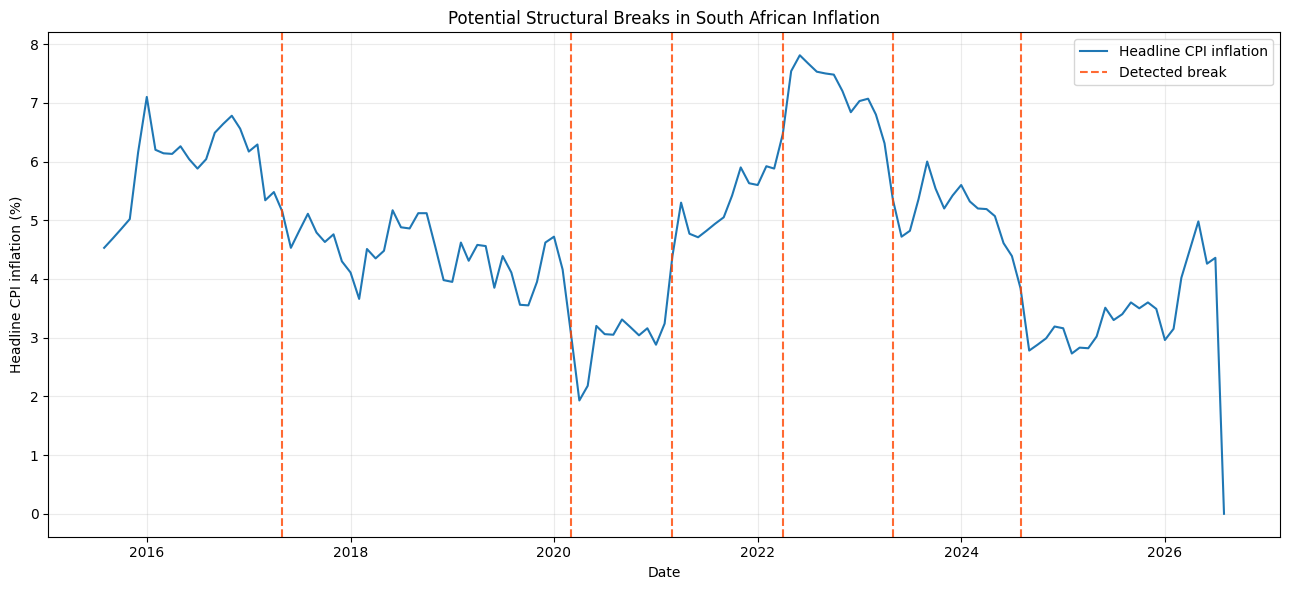

In [ ]:
# Visual representation of structural break dates
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    series.index,
    series,
    label="Headline CPI inflation"
)

for i, date in enumerate(break_dates):
    ax.axvline(
        date,
        color="#FF4500",
        linestyle="--",
        alpha=0.8,
        label="Detected break" if i == 0 else None
    )

ax.set_title("Potential Structural Breaks in South African Inflation")
ax.set_xlabel("Date")
ax.set_ylabel("Headline CPI inflation (%)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# Regression relationship stability test
from statsmodels.stats.diagnostic import breaks_cusumolsresid

cusum_stat, cusum_pvalue, critical_values = (
    breaks_cusumolsresid(
        model.resid,
        ddof=int(model.df_model) + 1
    )
)

print("CUSUM statistic:", cusum_stat)
print("CUSUM p-value:", cusum_pvalue)
print("Critical values:", critical_values)

CUSUM statistic: 2.571160549380931
CUSUM p-value: 3.6216314356204745e-06
Critical values: [(1, 1.63), (5, 1.36), (10, 1.22)]


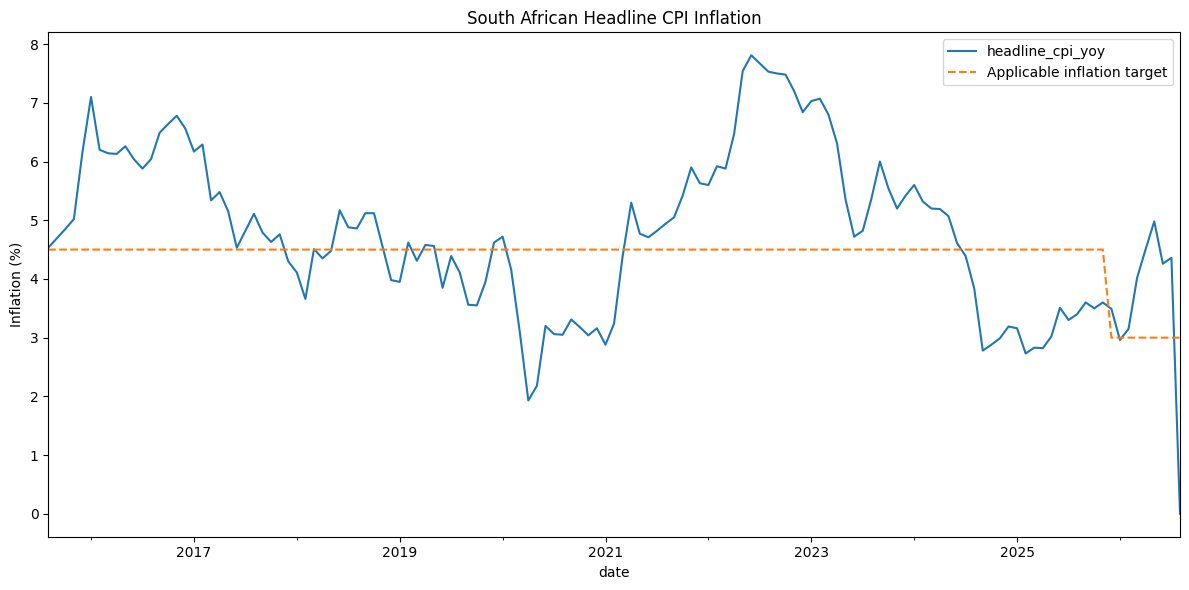

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

df["headline_cpi_yoy"].plot(
    ax=ax,
    title="South African Headline CPI Inflation"
)

df["inflation_target"].plot(
    ax=ax,
    linestyle="--",
    label="Applicable inflation target"
)

ax.set_ylabel("Inflation (%)")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Nonlinearity test. Baseline against the nonlinear specification
import statsmodels.formula.api as smf

# Baseline linear model
model_linear = smf.ols(
    "future_gaps ~ oil_change_pct + depreciation_pct",
    data=df
).fit()

# Add quadratic terms and an interaction
model_nonlinear = smf.ols(
    """
    future_gaps ~ oil_change_pct
    + depreciation_pct
    + I(oil_change_pct**2)
    + I(depreciation_pct**2)
    + oil_change_pct:depreciation_pct
    """,
    data=df
).fit()

print(model_linear.summary())
print(model_nonlinear.summary())

ValueError: endog has evaluated to an array with multiple columns that has shape (126, 6). This occurs when the variable converted to endog is non-numeric (e.g., bool or str).

In [ ]:
print(df.columns.tolist())

['headline_cpi_yoy', 'brent_usd', 'zar_usd', 'policy_rate', 'inflation_target', 'target_gap', 'absolute_target_gap', 'future_max_gap_6m', 'future_mean_gap_6m', 'oil_change_pct', 'depreciation_pct', 'joint_shock', 'gap_lag1', 'repo_lag1']


In [ ]:
display(df.head())

,headline_cpi_yoy,brent_usd,zar_usd,policy_rate,inflation_target,target_gap,absolute_target_gap,future_max_gap_6m,future_mean_gap_6m,oil_change_pct,depreciation_pct,joint_shock,gap_lag1,repo_lag1
date,,,,,,,,,,,,,,
2015-08-01,4.53,0.0175,-0.78,6.000,4.5,0.03,0.03,2.6,1.170000,NaN,NaN,0,NaN,NaN
2015-09-01,4.69,0.0140,4.60,6.000,4.5,0.19,0.19,2.6,1.411667,-20.000000,-689.743590,0,0.03,6.000
2015-10-01,4.85,-0.0777,5.74,6.083,4.5,0.35,0.35,2.6,1.625000,-655.000000,24.782609,0,0.19,6.000
2015-11-01,5.02,-0.1459,9.73,6.250,4.5,0.52,0.52,2.6,1.831667,87.773488,69.512195,0,0.35,6.083
2015-12-01,6.16,-0.1884,-3.75,6.274,4.5,1.66,1.66,2.6,1.811667,29.129541,-138.540596,0,0.52,6.250


In [ ]:
# Check for duplicate column names
print("Duplicate columns:", df.columns[df.columns.duplicated()].tolist())

# Inspect the dependent variable
print("Data type:", df["future_mean_gap_6m"].dtype)
print("First 10 values:")
print(df["future_mean_gap_6m"].head(10))

print("Unique values:")
print(df["future_mean_gap_6m"].nunique())
print(df["future_mean_gap_6m"].unique()[:10])

Duplicate columns: []
Data type: float64
First 10 values:
date
2015-08-01    1.170000
2015-09-01    1.411667
2015-10-01    1.625000
2015-11-01    1.831667
2015-12-01    1.811667
2016-01-01    1.608333
2016-02-01    1.581667
2016-03-01    1.640000
2016-04-01    1.725000
2016-05-01    1.811667
Name: future_mean_gap_6m, dtype: float64
Unique values:
131
[1.17       1.41166667 1.625      1.83166667 1.81166667 1.60833333
 1.58166667 1.64       1.725      1.81166667]


In [ ]:
# Baseline test with nonlinear specification
import statsmodels.formula.api as smf

# Baseline linear model
model_linear = smf.ols(
    "future_mean_gap_6m ~ oil_change_pct + depreciation_pct",
    data=df
).fit()

# Add quadratic terms and an interaction
model_nonlinear = smf.ols(
    """
    future_mean_gap_6m ~ oil_change_pct
    + depreciation_pct
    + I(oil_change_pct**2)
    + I(depreciation_pct**2)
    + oil_change_pct:depreciation_pct
    """,
    data=df
).fit()

print(model_linear.summary())
print(model_nonlinear.summary())

                            OLS Regression Results                            
Dep. Variable:     future_mean_gap_6m   R-squared:                       0.050
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     3.384
Date:                Wed, 28 Oct 2026   Prob (F-statistic):             0.0370
Time:                        15:05:34   Log-Likelihood:                -138.85
No. Observations:                 131   AIC:                             283.7
Df Residuals:                     128   BIC:                             292.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            1.1429      0.062  

In [ ]:
# Test for joint significance
# Joint test:
# oil_change_pct^2 = 0
# depreciation_pct^2 = 0
# oil_change_pct * depreciation_pct = 0

print(
    model_nonlinear.f_test(
        "I(oil_change_pct**2) = 0, "
        "I(depreciation_pct**2) = 0, "
        "oil_change_pct:depreciation_pct = 0"
    )
)

PatsyError: unrecognized token in constraint
    I(oil_change_pct**2) = 0, I(depreciation_pct**2) = 0, oil_change_pct:depreciation_pct = 0
    ^

In [ ]:
print(model_nonlinear.params.index.tolist())

['Intercept', 'oil_change_pct', 'depreciation_pct', 'I(oil_change_pct ** 2)', 'I(depreciation_pct ** 2)', 'oil_change_pct:depreciation_pct']


In [ ]:
print(
    model_nonlinear.f_test(
        "I(oil_change_pct ** 2) = 0, "
        "I(depreciation_pct ** 2) = 0, "
        "oil_change_pct:depreciation_pct = 0"
    )
)

<F test: F=0.18888787509171545, p=0.9037996672924681, df_denom=125, df_num=3>


In [ ]:
# Ramsey RESET Test
from statsmodels.stats.diagnostic import linear_reset

reset_result = linear_reset(
    model_linear,
    power=3,
    use_f=True
)

print(reset_result)
print("F-statistic:", reset_result.fvalue)
print("p-value:", reset_result.pvalue)

<F test: F=0.25241947301350764, p=0.7773106975437569, df_denom=126, df_num=2>
F-statistic: 0.25241947301350764
p-value: 0.7773106975437569


In [ ]:
#Critical value calculation
from scipy.stats import f

alpha = 0.05

f_critical = f.ppf(
    1 - alpha,
    reset_result.df_num,
    reset_result.df_denom
)

print("Critical F-value:", f_critical)

Critical F-value: 3.0681002689768526


In [ ]:
from statsmodels.stats.diagnostic import linear_reset
from scipy.stats import f

reset_result = linear_reset(
    model_linear,
    power=3,
    use_f=True
)

alpha = 0.05

f_stat = float(reset_result.fvalue)
p_value = float(reset_result.pvalue)

df_num = reset_result.df_num
df_denom = reset_result.df_denom

f_critical = f.ppf(
    1 - alpha,
    df_num,
    df_denom
)

print(f"F-statistic: {f_stat:.4f}")
print(f"Critical F-value: {f_critical:.4f}")
print(f"p-value: {p_value:.6f}")
print(f"Numerator degrees of freedom: {df_num}")
print(f"Denominator degrees of freedom: {df_denom}")

print("Decision using p-value:",
      "Reject H0" if p_value < alpha else "Do not reject H0")

print("Decision using critical value:",
      "Reject H0" if f_stat > f_critical else "Do not reject H0")

F-statistic: 0.2524
Critical F-value: 3.0681
p-value: 0.777311
Numerator degrees of freedom: 2.0
Denominator degrees of freedom: 126.0
Decision using p-value: Do not reject H0
Decision using critical value: Do not reject H0
